# Cloud detection on Sentinel-2 pixels

CatBoost classifier for Cloud, Snow, Water and Rest, evaluated under random and scene-based sampling.

**Outputs**
- `figures/`: Figure 1 (data overview) and Figure 2 (Cloud precision-recall and ROC curves)
- `results/`: data facts, fold sizes, holdout scenes, predictions and results tables
- `model/`: final models for use in the real-image notebook

%Run this notebook from the `repo` folder, with the training file in `data/`. Running it trains 12 models, then computes the confidence intervals.

## 0. Setup

In [1]:
# This cell loads the packages and defines the settings used throughout the notebook.
# Keeping paths and settings here makes the analysis easier to rerun and check.
# Folders are relative to this notebook, and the package versions are saved with the results.

import json
from importlib.metadata import version
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from matplotlib.lines import Line2D
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split

SEED = 42
THRESHOLD = 0.5    # a pixel counts as Cloud when P(Cloud) >= THRESHOLD
CAP = 30000        # max pixels per scene group in training and validation data
N_BOOT = 500       # bootstrap resamples for the confidence intervals

FILE = Path("data/20170710_s2_manual_classification_data.h5")
FIG_DIR, MODEL_DIR, RESULTS_DIR = Path("figures"), Path("model"), Path("results")
assert FILE.exists(), f"{FILE} not found. Run this notebook from the repo folder."

for folder in (FIG_DIR, MODEL_DIR, RESULTS_DIR):
    folder.mkdir(exist_ok=True)

packages = ["catboost", "cartopy", "h5py", "matplotlib", "numpy", "pandas", "scikit-learn", "scipy"]
versions = {p: version(p) for p in packages}
(RESULTS_DIR / "package_versions.json").write_text(json.dumps(versions, indent=2))
print(versions)

{'catboost': '1.2.8', 'cartopy': '0.26.0', 'h5py': '3.16.0', 'matplotlib': '3.10.8', 'numpy': '2.3.5', 'pandas': '2.3.3', 'scikit-learn': '1.8.0', 'scipy': '1.16.3'}


## 1. Load the data

In [2]:
# This cell lists what the HDF5 file contains, including its bands, classes, citation and licence.
# The file stores text as bytes, so the helper function converts it to normal strings.
# Nothing here changes the data.

def dec(a):
    """Convert byte strings from the file into normal text."""
    a = np.asarray(a)
    if a.dtype.kind == "S":
        return np.char.decode(a, "utf-8")
    if a.dtype.kind == "O":
        return np.array([x.decode() if isinstance(x, bytes) else x for x in a])
    return a

with h5py.File(FILE) as f:
    for name, item in f.items():
        print(f"{name:25s} shape={str(item.shape):15s} type={item.dtype}")

    print()
    print(pd.DataFrame({
        "band": dec(f["band"][()]),
        "wavelength_nm": f["central_wavelength_nm"][()],
        "bandwidth_nm": f["bandwidth_nm"][()],
        "resolution_m": f["spatial_sampling_m"][()],
    }).to_string(index=False))

    for k in ["cite", "licence"]:
        print(f"\n{k}:", dec(f[k][()]))

author                    shape=()              type=object
band                      shape=(13,)           type=|S2
bandwidth_nm              shape=(13,)           type=int16
central_wavelength_nm     shape=(13,)           type=int16
cite                      shape=()              type=object
class_ids                 shape=(6,)            type=int8
class_names               shape=(6,)            type=|S6
classes                   shape=(3028733,)      type=int8
continent                 shape=(3028733,)      type=|S32
dates                     shape=(3028733,)      type=|S16
granule_id                shape=(3028733,)      type=|S32
latitude                  shape=(3028733,)      type=float64
licence                   shape=()              type=object
longitude                 shape=(3028733,)      type=float64
product_id                shape=(3028733,)      type=|S85
spatial_sampling_m        shape=(13,)           type=int16
spectra                   shape=(3028733, 13)   type=float1

In [3]:
# This cell loads the spectra and pixel information, then merges linked products and granules into scene groups.
# A product and a granule are linked when they share pixels, so related data ends up in one connected group.
# Each scene group later stays entirely within one data partition.

with h5py.File(FILE) as f:
    X = f["spectra"][()].astype(np.float64)
    bands = np.array([f"B{b}" for b in dec(f["band"][()]).astype(str)])
    wavelengths = f["central_wavelength_nm"][()]
    names = dict(zip(f["class_ids"][()].tolist(), dec(f["class_names"][()]).tolist()))
    df = pd.DataFrame({
        "cls": pd.Series(f["classes"][()]).map(names),
        "product_id": dec(f["product_id"][()]),
        "granule_id": dec(f["granule_id"][()]),
        "latitude": f["latitude"][()],
        "longitude": f["longitude"][()],
    })

p, _ = pd.factorize(df["product_id"])
g, _ = pd.factorize(df["granule_id"])
g = g + p.max() + 1
n = g.max() + 1
graph = coo_matrix((np.ones(len(p)), (p, g)), shape=(n, n))
_, labels = connected_components(graph, directed=False)
df["group"] = labels[p]

CLASSES = ["Cloud", "Snow", "Cirrus", "Clear", "Water", "Shadow"]
COLORS = dict(zip(CLASSES, ["tab:orange", "tab:cyan", "tab:blue", "tab:green", "navy", "tab:gray"]))

print(df["cls"].value_counts().to_string())
print("Scene groups:", df["group"].nunique())
print("Bands:", bands)

cls
Clear     1040411
Cirrus     499372
Cloud      486430
Water      447811
Snow       417414
Shadow     137295
Scene groups: 39
Bands: ['B1' 'B2' 'B3' 'B4' 'B5' 'B6' 'B7' 'B8' 'B8a' 'B9' 'B10' 'B11' 'B12']


In [4]:
# This cell calculates the numbers quoted in the report's data section, using all labelled pixels.
# The share above 1 uses bands B1 to B8a, the bands used for that statement in the report.
# Everything is saved so that the report text can be checked against the data.

j = {b: i for i, b in enumerate(bands)}
product_sizes = df.groupby("product_id").size()
is_snow, is_cloud = df["cls"].to_numpy() == "Snow", df["cls"].to_numpy() == "Cloud"

facts = {
    "pixels": len(df),
    "missing_values": int(np.isnan(X).sum()),
    "negative_values": int((X < 0).sum()),
    "products": df["product_id"].nunique(),
    "granules": df["granule_id"].nunique(),
    "scene_groups": df["group"].nunique(),
    "smallest_product_pixels": int(product_sizes.min()),
    "largest_product_pixels": int(product_sizes.max()),
    "median_B10_all_pixels": float(np.median(X[:, j["B10"]])),
    "median_B11_snow": float(np.median(X[is_snow, j["B11"]])),
    "median_B11_cloud": float(np.median(X[is_cloud, j["B11"]])),
}
facts_table = pd.Series(facts, name="value").rename_axis("fact").reset_index()
facts_table.to_csv(RESULTS_DIR / "data_facts.csv", index=False)
print(facts_table.to_string(index=False))

above_1 = X[:, :j["B8a"] + 1].max(axis=1) > 1
class_table = df.groupby("cls").agg(pixels=("group", "size"), scene_groups=("group", "nunique")).reindex(CLASSES)
class_table["share_of_pixels"] = class_table["pixels"] / len(df)
class_table["share_above_1_B1_to_B8a"] = pd.Series(above_1).groupby(df["cls"].to_numpy()).mean()
class_table["pixels_above_1_B1_to_B8a"] = pd.Series(above_1).groupby(df["cls"].to_numpy()).sum()
class_table.to_csv(RESULTS_DIR / "class_summary.csv")
print()
print(class_table.round(4).to_string())

                   fact        value
                 pixels 3.028733e+06
         missing_values 0.000000e+00
        negative_values 0.000000e+00
               products 4.800000e+01
               granules 5.100000e+01
           scene_groups 3.900000e+01
smallest_product_pixels 4.345000e+03
 largest_product_pixels 2.186940e+05
  median_B10_all_pixels 2.099991e-03
        median_B11_snow 7.800293e-02
       median_B11_cloud 5.664062e-01

         pixels  scene_groups  share_of_pixels  share_above_1_B1_to_B8a  pixels_above_1_B1_to_B8a
cls                                                                                              
Cloud    486430            29           0.1606                   0.1479                     71955
Snow     417414            17           0.1378                   0.4923                    205488
Cirrus   499372            14           0.1649                   0.0000                         0
Clear   1040411            38           0.3435                   

## 2. Figure 1: data overview

/Users/varyabazilova/miniconda3/envs/alluvialfans/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/varyabazilova/miniconda3/envs/alluvialfans/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/varyabazilova/miniconda3/envs/alluvialfans/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/varyabazilova/miniconda3/envs/alluvialfans/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/varyabazilova/minicon

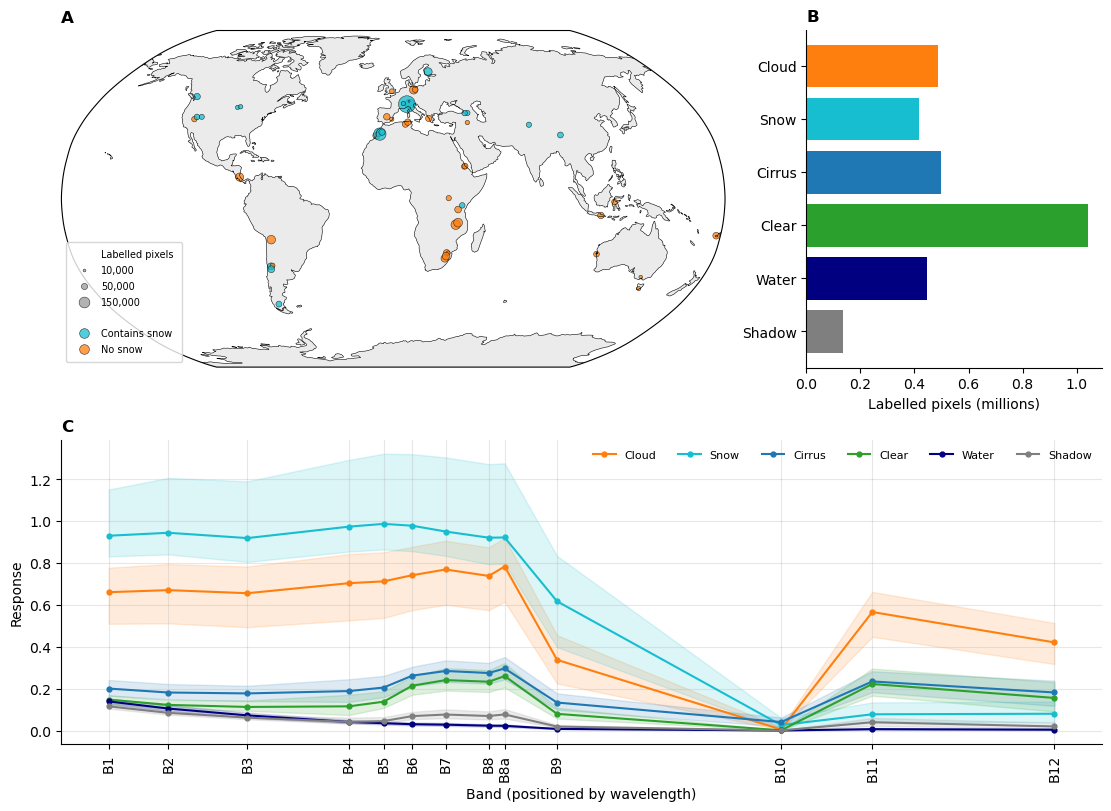

In [5]:
# Figure 1 shows where the labelled pixels come from, how many belong to each class, and each class's spectrum.
# Spectra are pooled across pixels, so scenes with more labelled pixels have more influence.
# The shading shows the interquartile range around each class's median.

fig, axd = plt.subplot_mosaic(
    "AAB;CCC",
    figsize=(11, 8),
    height_ratios=[1, 0.9],
    per_subplot_kw={"A": {"projection": ccrs.Robinson()}},
    layout="constrained",
)

# A: scene map
SIZE_DIV = 2500
ax = axd["A"]
pts = (df.groupby(["group", "granule_id"])
         .agg(lon=("longitude", "median"), lat=("latitude", "median"), pixels=("cls", "size"))
         .reset_index())
snow_granules = df.loc[df["cls"] == "Snow", "granule_id"].unique()
pts["has_snow"] = pts["granule_id"].isin(snow_granules)

ax.set_global()
ax.add_feature(cfeature.LAND, facecolor="0.92")
ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
ax.scatter(pts.lon, pts.lat, s=pts.pixels / SIZE_DIV,
           color=np.where(pts.has_snow, "tab:cyan", "tab:orange"),
           alpha=0.75, edgecolor="k", linewidth=0.4,
           transform=ccrs.PlateCarree())

def dot(color, size, label):
    return Line2D([], [], marker="o", linestyle="", color=color, alpha=0.75,
                  markeredgecolor="k", markeredgewidth=0.4, markersize=size, label=label)

heading = lambda text: Line2D([], [], linestyle="", label=text)
handles = [
    heading("Labelled pixels"),
    *[dot("0.6", np.sqrt(n / SIZE_DIV), f"{n:,}") for n in [10000, 50000, 150000]],
    heading(" "),
    dot("tab:cyan", 7, "Contains snow"),
    dot("tab:orange", 7, "No snow"),
]
ax.legend(handles=handles, loc="lower left", frameon=True, labelspacing=0.6, borderpad=0.8, fontsize=7)

# B: pixels per class
ax = axd["B"]
counts = df["cls"].value_counts().reindex(CLASSES)
ax.barh(CLASSES, counts / 1e6, color=[COLORS[c] for c in CLASSES])
ax.invert_yaxis()
ax.set_xlabel("Labelled pixels (millions)")
ax.spines[["top", "right"]].set_visible(False)

# C: spectral signatures
ax = axd["C"]
order = np.argsort(wavelengths)
cls_all = df["cls"].to_numpy()
for c in CLASSES:
    S = X[cls_all == c][:, order]
    q25, med, q75 = np.percentile(S, [25, 50, 75], axis=0)
    ax.plot(wavelengths[order], med, "-o", ms=3.5, color=COLORS[c], label=c)
    ax.fill_between(wavelengths[order], q25, q75, color=COLORS[c], alpha=0.15)
ax.set_xscale("log")
ax.set_xticks(wavelengths[order], bands[order], rotation=90)
ax.minorticks_off()
ax.set_xlabel("Band (positioned by wavelength)")
ax.set_ylabel("Response")
ax.grid(alpha=0.3)
ax.legend(ncols=6, fontsize=8, frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)

for key, a in axd.items():
    a.set_title(key, loc="left", fontweight="bold")

fig.savefig(FIG_DIR / "fig1_data_overview.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "fig1_data_overview.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Validation design

In [6]:
# This cell defines the target classes and sets aside holdout scene groups for the final test.
# The holdout is chosen from class coverage only, never from model scores.
# Its locations are saved, and the remaining development scenes are used for cross-validation.

TARGET_NAMES = ["Rest", "Cloud", "Snow", "Water"]
cls = df["cls"].to_numpy().astype(str)
groups = df["group"].to_numpy()
y = np.select([cls == "Cloud", cls == "Snow", cls == "Water"], [1, 2, 3], default=0)

holdout_groups = None
for seed in range(SEED, SEED + 100):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    _, candidate = next(sgkf.split(X, y, groups))
    gs = groups[candidate]
    enough = all(len(np.unique(gs[cls[candidate] == c])) >= 3
                 for c in ["Cloud", "Snow", "Water", "Cirrus"])
    if enough and 7 <= len(np.unique(gs)) <= 9:
        holdout_groups = np.unique(gs)
        print("Holdout chosen with seed", seed)
        break
assert holdout_groups is not None, "No holdout met the coverage rule"

is_holdout = np.isin(groups, holdout_groups)
holdout_idx = np.flatnonzero(is_holdout)
dev_idx = np.flatnonzero(~is_holdout)
assert not set(groups[dev_idx]) & set(groups[holdout_idx])

pd.Series(holdout_groups, name="group").to_csv(RESULTS_DIR / "holdout_groups.csv", index=False)
holdout_locations = (df[is_holdout]
                     .groupby(["group", "granule_id"])
                     .agg(lat=("latitude", "median"), lon=("longitude", "median"), pixels=("cls", "size"),
                          classes=("cls", lambda s: ", ".join(sorted(set(s)))))
                     .round(2))
holdout_locations.to_csv(RESULTS_DIR / "holdout_locations.csv")

print(f"Holdout: {len(holdout_groups)} groups, {len(holdout_idx):,} pixels")
print(f"Development: {len(np.unique(groups[dev_idx]))} groups, {len(dev_idx):,} pixels")
print(holdout_locations.to_string())

Holdout chosen with seed 42
Holdout: 9 groups, 575,439 pixels
Development: 30 groups, 2,453,294 pixels
                    lat     lon  pixels                                    classes
group granule_id                                                                  
3     32TNS       46.80    9.67    4345                        Cloud, Shadow, Snow
5     35VLJ       61.78   24.08   87677  Cirrus, Clear, Cloud, Shadow, Snow, Water
9     54HYD      -37.51  143.97   17211                        Clear, Cloud, Water
17    38SLF       36.54   42.93   25022                               Clear, Water
19    19FCD      -50.67  -71.79   45044                  Clear, Cloud, Snow, Water
21    10UEV       49.15 -121.85   53596                 Clear, Shadow, Snow, Water
22    19HDE      -32.37  -69.71   61275         Cirrus, Clear, Cloud, Shadow, Snow
      19HEE      -32.00  -68.66   32090                       Clear, Cloud, Shadow
27    30UXC       51.80   -0.92   30485                Cirrus, Clea

In [7]:
# This cell builds the two sampling strategies, using development scenes only.
# Random sampling can place pixels from one scene on both sides of a split, while scene sampling keeps each group on one side.
# Large scenes are capped in training and validation data, while test folds stay complete.

def cap_per_group(idx, seed=SEED):
    if CAP is None:
        return idx
    rng = np.random.default_rng(seed)
    kept = []
    for grp in np.unique(groups[idx]):
        members = idx[groups[idx] == grp]
        if len(members) > CAP:
            members = rng.choice(members, CAP, replace=False)
        kept.append(members)
    return np.concatenate(kept)

def random_folds():
    folds = []
    outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for a, b in outer.split(dev_idx, y[dev_idx]):
        dev, te = dev_idx[a], dev_idx[b]
        tr, va = train_test_split(dev, test_size=0.2, stratify=y[dev], random_state=SEED)
        folds.append({"train": cap_per_group(tr), "val": cap_per_group(va), "test": te})
    return folds

def scene_folds():
    folds = []
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    for a, b in outer.split(dev_idx, y[dev_idx], groups[dev_idx]):
        dev, te = dev_idx[a], dev_idx[b]
        inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
        i, j_ = next(inner.split(dev, y[dev], groups[dev]))
        tr, va = dev[i], dev[j_]
        assert not set(groups[tr]) & set(groups[te])
        assert not set(groups[tr]) & set(groups[va])
        assert not set(groups[va]) & set(groups[te])
        folds.append({"train": cap_per_group(tr), "val": cap_per_group(va), "test": te})
    return folds

folds_by_strategy = {"Random": random_folds(), "Scene": scene_folds()}

for strategy, folds in folds_by_strategy.items():
    tested = np.concatenate([s["test"] for s in folds])
    assert len(tested) == len(dev_idx) and set(tested) == set(dev_idx), "Each development pixel must be tested once"
    for s in folds:
        assert not set(groups[np.r_[s["train"], s["val"], s["test"]]]) & set(holdout_groups)
print("All leakage checks passed")

rows = []
for strategy, folds in folds_by_strategy.items():
    for k, s in enumerate(folds):
        for part in ["train", "val", "test"]:
            rows.append({"strategy": strategy, "fold": k, "part": part, "pixels": len(s[part]),
                         "scene_groups": len(np.unique(groups[s[part]]))})
fold_sizes = pd.DataFrame(rows)
fold_sizes.to_csv(RESULTS_DIR / "fold_sizes.csv", index=False)
print(fold_sizes.pivot_table(index=["strategy", "fold"], columns="part",
                             values=["pixels", "scene_groups"]).to_string())

All leakage checks passed
                 pixels                     scene_groups            
part               test     train       val         test train   val
strategy fold                                                       
Random   0     490659.0  802113.0  338191.0         30.0  30.0  30.0
         1     490659.0  801992.0  338308.0         30.0  30.0  30.0
         2     490659.0  802376.0  338464.0         30.0  30.0  30.0
         3     490659.0  802232.0  338285.0         30.0  30.0  30.0
         4     490658.0  802027.0  338334.0         30.0  30.0  30.0
Scene    0     486381.0  675489.0   83808.0          4.0  23.0   3.0
         1     482749.0  723278.0   60000.0          3.0  25.0   2.0
         2     477665.0  640874.0   60000.0          6.0  22.0   2.0
         3     489474.0  459470.0  173808.0          8.0  16.0   6.0
         4     517025.0  526385.0   90000.0          9.0  18.0   3.0


## 4. Cross-validation

In [8]:
# CatBoost is a gradient-boosted tree model, here predicting Cloud, Snow, Water or Rest for each pixel.
# It adds small trees one at a time, and the validation set decides when to stop.
# Each test fold is predicted by a model that did not train on it, and the predictions are pooled for scoring.

def new_model():
    return CatBoostClassifier(loss_function="MultiClass", iterations=500, depth=6,
                              learning_rate=0.1, od_type="Iter", od_wait=30,
                              random_seed=SEED, verbose=False)

def run_catboost(folds, name):
    oof = np.full((len(y), len(TARGET_NAMES)), np.nan)
    best = []
    for k, s in enumerate(folds):
        model = new_model()
        model.fit(X[s["train"]], y[s["train"]], eval_set=(X[s["val"]], y[s["val"]]), use_best_model=True)
        oof[s["test"]] = model.predict_proba(X[s["test"]])
        best.append({"strategy": name, "fold": k, "best_iteration": model.get_best_iteration()})
        print(f"{name}, fold {k}: best iteration {model.get_best_iteration()}")
    return oof, best

oof_random, best_random = run_catboost(folds_by_strategy["Random"], "Random")
oof_scene, best_scene = run_catboost(folds_by_strategy["Scene"], "Scene")

pd.DataFrame(best_random + best_scene).to_csv(RESULTS_DIR / "best_iterations.csv", index=False)
np.savez_compressed(RESULTS_DIR / "oof_predictions.npz", random=oof_random[dev_idx], scene=oof_scene[dev_idx],
                    dev_idx=dev_idx, y=y[dev_idx], groups=groups[dev_idx], cls=cls[dev_idx])

def metrics_by_class(name, p, t):
    pred = p.argmax(1)
    row = {"strategy": name}
    for i, c in enumerate(TARGET_NAMES):
        tp = ((pred == i) & (t == i)).sum()
        row[f"{c}_recall"] = tp / (t == i).sum()
        row[f"{c}_precision"] = tp / max((pred == i).sum(), 1)
    return row

by_class = pd.DataFrame([metrics_by_class("Random", oof_random[dev_idx], y[dev_idx]),
                         metrics_by_class("Scene", oof_scene[dev_idx], y[dev_idx])]).set_index("strategy")
by_class.to_csv(RESULTS_DIR / "cv_metrics_by_class.csv")
print("\nMost likely class, by class")
print(by_class.T.round(4).to_string())

Random, fold 0: best iteration 499
Random, fold 1: best iteration 499
Random, fold 2: best iteration 499
Random, fold 3: best iteration 499
Random, fold 4: best iteration 499
Scene, fold 0: best iteration 71
Scene, fold 1: best iteration 122
Scene, fold 2: best iteration 68
Scene, fold 3: best iteration 62
Scene, fold 4: best iteration 145

Most likely class, by class
strategy         Random   Scene
Rest_recall      0.9985  0.9688
Rest_precision   0.9967  0.9667
Cloud_recall     0.9939  0.9202
Cloud_precision  0.9962  0.9097
Snow_recall      0.9959  0.9820
Snow_precision   0.9992  0.9899
Water_recall     0.9962  0.9629
Water_precision  0.9975  0.9760


## 5. Sanity check

In [9]:
# This checks for pipeline bugs by training on deliberately shuffled training labels.
# With no real link between spectra and labels, the model should have no skill on test scenes.
# Cloud PR-AUC should therefore fall to about the share of Cloud pixels in the test fold.

rng = np.random.default_rng(SEED)
s = folds_by_strategy["Scene"][0]
shuffled_model = CatBoostClassifier(loss_function="MultiClass", iterations=100, depth=6,
                                    learning_rate=0.1, random_seed=SEED, verbose=False)
shuffled_model.fit(X[s["train"]], rng.permutation(y[s["train"]]))
p_shuffled = shuffled_model.predict_proba(X[s["test"]])[:, 1]

shuffled_check = pd.DataFrame([{
    "cloud_pr_auc_shuffled_labels": average_precision_score(y[s["test"]] == 1, p_shuffled),
    "cloud_share_in_test_fold": (y[s["test"]] == 1).mean(),
}])
shuffled_check.to_csv(RESULTS_DIR / "shuffled_label_check.csv", index=False)
print(shuffled_check.round(3).to_string(index=False))

 cloud_pr_auc_shuffled_labels  cloud_share_in_test_fold
                        0.134                     0.141


## 6. Final models and holdout predictions

In [10]:
# One final model is trained per sampling strategy, using development scenes only.
# Model settings stay the same, and each strategy selects its validation data in its own way.
# Both models then predict the same holdout scenes, and the scene-based model is saved for the real-image notebook.

rand_tr, rand_va = train_test_split(dev_idx, test_size=0.2, stratify=y[dev_idx], random_state=SEED)
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
a, b = next(inner.split(dev_idx, y[dev_idx], groups[dev_idx]))
scene_tr, scene_va = dev_idx[a], dev_idx[b]
assert not set(groups[scene_tr]) & set(groups[scene_va])

final_sets = {"Random": (cap_per_group(rand_tr), cap_per_group(rand_va)),
              "Scene": (cap_per_group(scene_tr), cap_per_group(scene_va))}

holdout_p, final_best = {}, []
for name, (tr, va) in final_sets.items():
    assert not set(groups[np.r_[tr, va]]) & set(holdout_groups)
    model = new_model()
    model.fit(X[tr], y[tr], eval_set=(X[va], y[va]), use_best_model=True)
    model.save_model(str(MODEL_DIR / f"final_{name.lower()}_4class.cbm"))
    holdout_p[name] = model.predict_proba(X[holdout_idx])
    final_best.append({"strategy": name, "best_iteration": model.get_best_iteration()})
    print(f"{name}: best iteration {model.get_best_iteration()}")

pd.DataFrame(final_best).to_csv(RESULTS_DIR / "final_best_iterations.csv", index=False)
np.savez_compressed(RESULTS_DIR / "holdout_predictions.npz", random=holdout_p["Random"], scene=holdout_p["Scene"],
                    holdout_idx=holdout_idx, y=y[holdout_idx], groups=groups[holdout_idx], cls=cls[holdout_idx])

with open(MODEL_DIR / "final_scene_4class.json", "w") as f:
    json.dump({"classes": TARGET_NAMES, "band_order": bands.tolist(), "cloud_threshold": THRESHOLD,
               "input": "top-of-atmosphere reflectance (Sentinel-2 Level-1C)"}, f, indent=2)
print("Saved:", sorted(p_.name for p_ in MODEL_DIR.iterdir()))

Random: best iteration 499
Scene: best iteration 143
Saved: ['.DS_Store', 'final_random_4class.cbm', 'final_scene_4class.cbm', 'final_scene_4class.json']


## 7. Figure 2: Cloud precision-recall and ROC curves

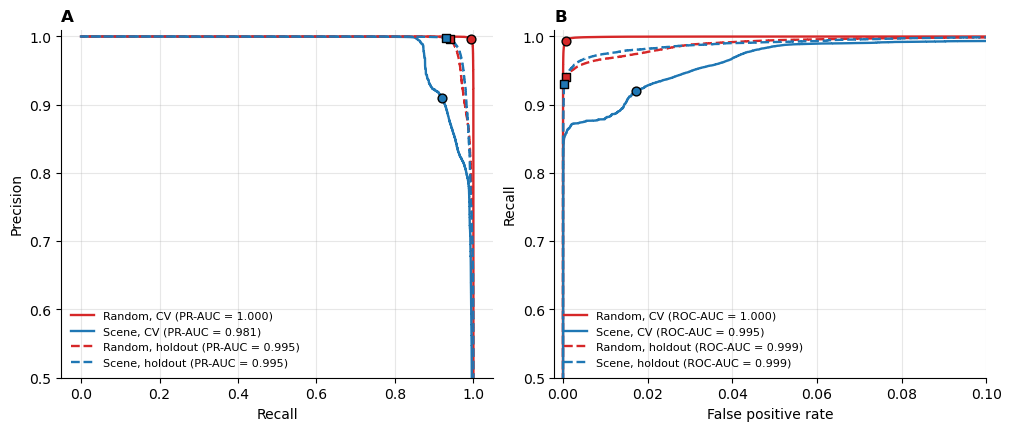

In [11]:
# These curves show how well each model ranks Cloud pixels across all possible thresholds.
# Solid lines show pooled cross-validation test folds, and dashed lines show the holdout scenes.
# Markers show performance at the chosen P(Cloud) threshold.

evaluations = {
    "Random, CV": (oof_random[dev_idx], y[dev_idx] == 1, groups[dev_idx], cls[dev_idx], "tab:red", "-", "o"),
    "Scene, CV": (oof_scene[dev_idx], y[dev_idx] == 1, groups[dev_idx], cls[dev_idx], "tab:blue", "-", "o"),
    "Random, holdout": (holdout_p["Random"], y[holdout_idx] == 1, groups[holdout_idx], cls[holdout_idx],
                        "tab:red", "--", "s"),
    "Scene, holdout": (holdout_p["Scene"], y[holdout_idx] == 1, groups[holdout_idx], cls[holdout_idx],
                       "tab:blue", "--", "s"),
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")

for name, (p, truth, _, _, color, style, marker) in evaluations.items():
    p_cloud = p[:, 1]
    pred = p_cloud >= THRESHOLD
    tn, fp, fn, tp = confusion_matrix(truth, pred).ravel()

    precision_curve, recall_curve, _ = precision_recall_curve(truth, p_cloud)
    axes[0].plot(recall_curve, precision_curve, color=color, ls=style, lw=1.7,
                 label=f"{name} (PR-AUC = {average_precision_score(truth, p_cloud):.3f})")
    axes[0].scatter(tp / (tp + fn), tp / (tp + fp), color=color, marker=marker, edgecolor="k", s=40, zorder=3)

    fpr, tpr, _ = roc_curve(truth, p_cloud)
    axes[1].plot(fpr, tpr, color=color, ls=style, lw=1.7,
                 label=f"{name} (ROC-AUC = {roc_auc_score(truth, p_cloud):.3f})")
    axes[1].scatter(fp / (fp + tn), tp / (tp + fn), color=color, marker=marker, edgecolor="k", s=40, zorder=3)

axes[0].set(xlabel="Recall", ylabel="Precision", ylim=(0.5, 1.01))
axes[0].set_title("A", loc="left", fontweight="bold")
axes[1].set(xlabel="False positive rate", ylabel="Recall", xlim=(-0.002, 0.1), ylim=(0.5, 1.01))
axes[1].set_title("B", loc="left", fontweight="bold")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig(FIG_DIR / "fig2_cloud_curves.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "fig2_cloud_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Results table

In [12]:
# This table reports Cloud results at P(Cloud) >= 0.5 for both sampling strategies and both evaluations.
# Confidence intervals resample whole scene groups, because pixels within a scene are not independent.
# Within cross-validation or holdout, both strategies use the same resamples, so their intervals are comparable.

def cloud_metrics(p_cloud, truth, pred):
    tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[False, True]).ravel()
    return {"recall": tp / max(tp + fn, 1), "precision": tp / max(tp + fp, 1),
            "PR_AUC": average_precision_score(truth, p_cloud),
            "TP": tp, "FN": fn, "FP": fp, "TN": tn}

def scene_bootstrap(p_cloud, truth, grp):
    rng = np.random.default_rng(SEED)
    unique_groups = np.unique(grp)
    where = {u: np.flatnonzero(grp == u) for u in unique_groups}
    rows = []
    for _ in range(N_BOOT):
        drawn = rng.choice(unique_groups, len(unique_groups), replace=True)
        i = np.concatenate([where[u] for u in drawn])
        if truth[i].any():
            m = cloud_metrics(p_cloud[i], truth[i], p_cloud[i] >= THRESHOLD)
            rows.append({k: m[k] for k in ["recall", "precision", "PR_AUC"]})
    return pd.DataFrame(rows).quantile([0.025, 0.975])

rows = []
for name, (p, truth, grp, _, *_rest) in evaluations.items():
    p_cloud = p[:, 1]
    strategy, evaluation = name.split(", ")
    m = cloud_metrics(p_cloud, truth, p_cloud >= THRESHOLD)
    ci = scene_bootstrap(p_cloud, truth, grp)
    row = {"strategy": strategy, "evaluation": evaluation, **m}
    for metric in ["recall", "precision", "PR_AUC"]:
        row[f"{metric}_low"], row[f"{metric}_high"] = ci.loc[0.025, metric], ci.loc[0.975, metric]
    rows.append(row)
    print(f"{name}: done")

results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "table_cloud_results.csv", index=False)
print(results.round(3).to_string(index=False))

Random, CV: done
Scene, CV: done
Random, holdout: done
Scene, holdout: done
strategy evaluation  recall  precision  PR_AUC     TP    FN    FP      TN  recall_low  recall_high  precision_low  precision_high  PR_AUC_low  PR_AUC_high
  Random         CV   0.994      0.996   1.000 391964  2445  1383 2057502       0.991        0.996          0.992           0.999       1.000        1.000
   Scene         CV   0.920      0.910   0.981 362767 31642 35700 2023185       0.858        0.972          0.794           0.972       0.961        0.993
  Random    holdout   0.941      0.996   0.995  86552  5469   352  483066       0.719        0.994          0.981           0.999       0.940        1.000
   Scene    holdout   0.930      0.998   0.995  85569  6452   140  483278       0.700        0.988          0.991           1.000       0.950        1.000


In [13]:
# This cell writes the results as a LaTeX table for the report.
# Values and intervals come directly from the results above, so the table can be regenerated after a new run.
# Values that would round to 1.000 are written as >0.999, because they are not exactly perfect.

def fmt(value):
    return ">0.999" if value > 0.999 else f"{value:.3f}"

order_ = [("Random", "CV"), ("Random", "holdout"), ("Scene", "CV"), ("Scene", "holdout")]
lookup = {(r.strategy, r.evaluation): r for r in results.itertuples()}

def metric_row(label, metric):
    cells_ = []
    for key in order_:
        r = lookup[key]
        low, high = getattr(r, f"{metric}_low"), getattr(r, f"{metric}_high")
        cells_.append(f"{fmt(getattr(r, metric))} ({low:.2f}--{high:.2f})")
    return f"        {label} & " + " & ".join(cells_) + r" \\"

def count_row(label):
    return f"        {label} & " + " & ".join(f"{getattr(lookup[k], label):,}" for k in order_) + r" \\"

latex = "\n".join([
    r"\begin{table}[htbp]",
    r"    \centering",
    r"    \small",
    r"    \caption{Cloud detection at $P(\mathrm{Cloud}) \geq 0.5$ under random and scene-based sampling. Parentheses show 95\% intervals from resampling whole scene groups. Cirrus is counted as not cloud.}",
    r"    \label{tab:cloud_performance}",
    r"    \begin{tabular}{lcccc}",
    r"        \toprule",
    r"        & \multicolumn{2}{c}{Random} & \multicolumn{2}{c}{Scene} \\",
    r"        \cmidrule(lr){2-3} \cmidrule(lr){4-5}",
    r"        Metric & CV & Holdout & CV & Holdout \\",
    r"        \midrule",
    metric_row("Recall", "recall"),
    metric_row("Precision", "precision"),
    metric_row("PR-AUC", "PR_AUC"),
    r"        \midrule",
    *[count_row(k) for k in ["TP", "FN", "FP", "TN"]],
    r"        \bottomrule",
    r"    \end{tabular}",
    r"\end{table}",
])
(RESULTS_DIR / "table_cloud_results.tex").write_text(latex + "\n")
print(latex)

\begin{table}[htbp]
    \centering
    \small
    \caption{Cloud detection at $P(\mathrm{Cloud}) \geq 0.5$ under random and scene-based sampling. Parentheses show 95\% intervals from resampling whole scene groups. Cirrus is counted as not cloud.}
    \label{tab:cloud_performance}
    \begin{tabular}{lcccc}
        \toprule
        & \multicolumn{2}{c}{Random} & \multicolumn{2}{c}{Scene} \\
        \cmidrule(lr){2-3} \cmidrule(lr){4-5}
        Metric & CV & Holdout & CV & Holdout \\
        \midrule
        Recall & 0.994 (0.99--1.00) & 0.941 (0.72--0.99) & 0.920 (0.86--0.97) & 0.930 (0.70--0.99) \\
        Precision & 0.996 (0.99--1.00) & 0.996 (0.98--1.00) & 0.910 (0.79--0.97) & 0.998 (0.99--1.00) \\
        PR-AUC & >0.999 (1.00--1.00) & 0.995 (0.94--1.00) & 0.981 (0.96--0.99) & 0.995 (0.95--1.00) \\
        \midrule
        TP & 391,964 & 86,552 & 362,767 & 85,569 \\
        FN & 2,445 & 5,469 & 31,642 & 6,452 \\
        FP & 1,383 & 352 & 35,700 & 140 \\
        TN & 2,057,502 & 48

## 9. Error breakdown and supporting tables

In [14]:
# This table shows how each original class is treated at the P(Cloud) threshold, for the report's discussion.
# It separates opaque cloud that was missed from other classes that were flagged as Cloud.
# It also compares the threshold with the most-likely-class rule used in earlier runs.

breakdown_rows, comparison_rows = [], []
for name, (p, truth, _, true_class, *_rest) in evaluations.items():
    strategy, evaluation = name.split(", ")
    pred = p[:, 1] >= THRESHOLD
    false_alarms = (pred & ~truth).sum()
    for c in CLASSES:
        m = true_class == c
        breakdown_rows.append({"strategy": strategy, "evaluation": evaluation, "true_class": c,
                               "pixels": m.sum(), "predicted_cloud": (pred & m).sum(),
                               "share_predicted_cloud": (pred & m).sum() / m.sum(),
                               "share_of_false_alarms": (pred & m).sum() / false_alarms if c != "Cloud" else np.nan})

    for rule, rule_pred in [("P(Cloud) >= 0.5", pred), ("Most likely class", p.argmax(1) == 1)]:
        tn, fp, fn, tp = confusion_matrix(truth, rule_pred).ravel()
        comparison_rows.append({"strategy": strategy, "evaluation": evaluation, "rule": rule,
                                "recall": tp / (tp + fn), "precision": tp / (tp + fp), "FN": fn, "FP": fp})

breakdown = pd.DataFrame(breakdown_rows)
breakdown.to_csv(RESULTS_DIR / "class_breakdown.csv", index=False)
print(breakdown.round(4).to_string(index=False))

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(RESULTS_DIR / "threshold_comparison.csv", index=False)
print()
print(comparison.round(4).to_string(index=False))

strategy evaluation true_class  pixels  predicted_cloud  share_predicted_cloud  share_of_false_alarms
  Random         CV      Cloud  394409           391964                 0.9938                    NaN
  Random         CV       Snow  343109              420                 0.0012                 0.3037
  Random         CV     Cirrus  352879              107                 0.0003                 0.0774
  Random         CV      Clear  899813              855                 0.0010                 0.6182
  Random         CV      Water  356173                0                 0.0000                 0.0000
  Random         CV     Shadow  106911                1                 0.0000                 0.0007
   Scene         CV      Cloud  394409           362767                 0.9198                    NaN
   Scene         CV       Snow  343109             2031                 0.0059                 0.0569
   Scene         CV     Cirrus  352879            23312                 0.0661    

In [15]:
# This table checks how closely P(Cloud) matches how often pixels really are cloud.
# It covers scene-based cross-validation and the holdout, using ten equal-width probability bins.
# A small overall error can hide problems in the middle bins, because most pixels sit near 0 or 1.

calibration_rows = []
for name in ["Scene, CV", "Scene, holdout"]:
    p, truth, *_rest = evaluations[name]
    p_cloud = p[:, 1]
    which = np.clip(np.digitize(p_cloud, np.linspace(0, 1, 11)) - 1, 0, 9)
    for b in range(10):
        m = which == b
        if m.any():
            calibration_rows.append({"evaluation": name, "bin": f"{b / 10:.1f}-{(b + 1) / 10:.1f}", "pixels": m.sum(),
                                     "mean_p_cloud": p_cloud[m].mean(), "cloud_share": truth[m].mean()})

calibration = pd.DataFrame(calibration_rows)
calibration["abs_gap"] = (calibration["mean_p_cloud"] - calibration["cloud_share"]).abs()
calibration.to_csv(RESULTS_DIR / "calibration_table.csv", index=False)
print(calibration.round(3).to_string(index=False))

for name, t in calibration.groupby("evaluation"):
    print(f"{name}: ECE = {(t['pixels'] / t['pixels'].sum() * t['abs_gap']).sum():.4f}")

    evaluation     bin  pixels  mean_p_cloud  cloud_share  abs_gap
     Scene, CV 0.0-0.1 1995690         0.005        0.007    0.003
     Scene, CV 0.1-0.2   20625         0.142        0.245    0.104
     Scene, CV 0.2-0.3   14548         0.250        0.292    0.041
     Scene, CV 0.3-0.4   12936         0.348        0.268    0.080
     Scene, CV 0.4-0.5   11028         0.448        0.365    0.083
     Scene, CV 0.5-0.6    9037         0.548        0.525    0.024
     Scene, CV 0.6-0.7    7569         0.648        0.676    0.028
     Scene, CV 0.7-0.8    8673         0.756        0.413    0.342
     Scene, CV 0.8-0.9   20090         0.868        0.229    0.639
     Scene, CV 0.9-1.0  353098         0.990        0.976    0.014
Scene, holdout 0.0-0.1  483706         0.002        0.006    0.004
Scene, holdout 0.1-0.2    3454         0.140        0.461    0.321
Scene, holdout 0.2-0.3    1212         0.244        0.634    0.389
Scene, holdout 0.3-0.4     696         0.347        0.806    0